## 0. Check GPU

# Fine-tuning and Evaluation of BGE-M3 — Ampara AI (dataset v2)

**Required files** (upload to `/content` before running; they come from `peru-legal-rag-data`):
- `training.json` — `generacion_dataset/data/output/dataset_v2/training.json` (one row per (question, positive), 10 judge-verified negatives)
- `document_chunks_all.jsonl` — 893-chunk corpus (`recoleccion/data/processed/`)
- `eval_dev_queries.jsonl`, `eval_dev_qrels.jsonl` (strict: source chunk) and `eval_dev_qrels_pooled.jsonl` (source + judge "yes" from pooling)

**Notebook flow:**
1. Check GPU · 2. Install dependencies · 3. Configure paths and hyperparameters
4. Explore the dataset · 5. Prepare the **dev** evaluation (the test set is not used here)
6. Fine-tuning with `torchrun` + `encoder_only.m3` module (5 epochs, one checkpoint per epoch)
7. Evaluate BASE, FINE-TUNED and **all checkpoints on dev**; the best one is chosen by **strict** NDCG@10
8. Save the chosen checkpoint to Drive and export to ONNX int8

> Strict qrels = source chunk (never seen in train). Pooled qrels = source + other chunks the judge marked "yes"; some of them are in train, so pooled is informative only.
> The test set is evaluated once, outside this notebook, with the checkpoint chosen on dev.
> Recall@k is reported as hits/min(|G|,k), same as the backend ablation, in addition to the FlagEmbedding metrics.

In [ ]:
!nvidia-smi
import torch
print(f"\nCUDA available  : {torch.cuda.is_available()}")
print(f"GPUs detected  : {torch.cuda.device_count()}")
if torch.cuda.is_available():
    print(f"GPU 0           : {torch.cuda.get_device_name(0)}")
    print(f"VRAM            : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Thu Oct 22 15:40:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   39C    P8             13W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 1. Install dependencies

In [ ]:
!pip install -q -U \
    FlagEmbedding \
    pytrec_eval \
    datasets \
    transformers \
    accelerate \
    peft \
    deepspeed
print('Dependencies installed')

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 95.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.5/250.5 kB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 48.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 145.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 48.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.0/54.0 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.8/947.8 kB 58.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 19.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.
Depen

In [ ]:
import json
import numpy as np
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("BAAI/bge-m3")

# Load all positives of the dataset
lengths = []
long_examples = []

with open("/content/training.json", "r") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        sample = json.loads(line)
        pos = sample["pos"]
        text = pos[0] if isinstance(pos, list) else pos
        tokens = tokenizer(text, truncation=False)["input_ids"]
        lengths.append(len(tokens))
        if len(tokens) > 512:
            long_examples.append((len(tokens), text[:150]))

lengths = np.array(lengths)

print(f"Total documents analyzed  : {len(lengths)}")
print(f"Mean length                : {lengths.mean():.0f} tokens")
print(f"Median length              : {np.median(lengths):.0f} tokens")
print(f"75th percentile            : {np.percentile(lengths, 75):.0f} tokens")
print(f"90th percentile            : {np.percentile(lengths, 90):.0f} tokens")
print(f"95th percentile            : {np.percentile(lengths, 95):.0f} tokens")
print(f"Maximum                    : {lengths.max():.0f} tokens")
print(f"Documents > 512 tokens     : {len(long_examples)} ({len(long_examples)/len(lengths)*100:.1f}%)")

if long_examples:
    print(f"\nTruncated examples (5 longest):")
    for length, text in sorted(long_examples, reverse=True)[:5]:
        print(f"  [{length} tokens] {text}...")

config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/444 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

Total documents analyzed  : 2057
Mean length                : 362 tokens
Median length              : 342 tokens
75th percentile            : 537 tokens
90th percentile            : 639 tokens
95th percentile            : 709 tokens
Maximum                    : 1437 tokens
Documents > 512 tokens     : 567 (27.6%)

Truncated examples (5 longest):
  [1437 tokens] 1. Al término del plazo de la detención policial establecido en el artículo 264, el Fiscal debe solicitar al Juez de la investigación preparatoria la ...
  [1437 tokens] 1. Al término del plazo de la detención policial establecido en el artículo 264, el Fiscal debe solicitar al Juez de la investigación preparatoria la ...
  [1437 tokens] 1. Al término del plazo de la detención policial establecido en el artículo 264, el Fiscal debe solicitar al Juez de la investigación preparatoria la ...
  [1437 tokens] 1. Al término del plazo de la detención policial establecido en el artículo 264, el Fiscal debe solicitar al Juez de la invest

## 2. Paths and hyperparameters configuration

> `BATCH_SIZE` and `GRAD_ACCUM` are set for the L4 GPU:
> - **L4  (~24 GB):** `BATCH_SIZE=1`, `GRAD_ACCUM=16`

In [ ]:
import os, json, torch, gc, shutil
from pathlib import Path
from collections import defaultdict

# ── Rutas ───────────────────────────────────────────────────────
DATA_DIR      = Path("/content")

TRAINING_FILE      = DATA_DIR / "training.json"
CORPUS_SRC         = DATA_DIR / "document_chunks_all.jsonl"      # 893-chunk corpus (chunk_id, text)
QUERIES_FILE       = DATA_DIR / "eval_dev_queries.jsonl"          # DEV (130 questions)
QRELS_FILE         = DATA_DIR / "eval_dev_qrels.jsonl"            # strict: source chunk only
QRELS_POOLED_FILE  = DATA_DIR / "eval_dev_qrels_pooled.jsonl"     # source + judge "yes" from pooling (Codex)

# Derived files (content-deduplicated corpus and translated qrels)
CORPUS_FIXED       = DATA_DIR / "corpus_fixed.jsonl"
QRELS_FIXED        = DATA_DIR / "dev_qrels_fixed.jsonl"
QRELS_POOLED_FIXED = DATA_DIR / "dev_qrels_pooled_fixed.jsonl"

# ── Model ──────────────────────────────────────────────────────
BASE_MODEL    = "BAAI/bge-m3"
OUTPUT_DIR    = "/content/bge-m3-legal-peru"
CACHE_MODEL   = "/content/cache/model"
CACHE_DATA    = "/content/cache/data"

# ── Hyperparameters (run A, the only one) ──────────────────────────
NUM_EPOCHS    = 5      # one checkpoint per epoch; the epoch is chosen on dev
BATCH_SIZE    = 1
GRAD_ACCUM    = 16
LEARNING_RATE = 5e-6
MAX_LEN       = 2048   # no corpus chunk exceeds 1558 tokens: nothing is truncated
TEMPERATURE   = 0.05
TRAIN_GROUP_SIZE = 11  # 1 positive + 10 negatives
K_VALUES      = [1, 3, 5, 10, 20, 100]

N_GPUS = torch.cuda.device_count()
print(f"Training GPUs          : {N_GPUS}")
print(f"Effective batch        : {BATCH_SIZE * GRAD_ACCUM}")
du = shutil.disk_usage("/content")
print(f"Free disk in /content : {du.free/1e9:.0f} GB (each checkpoint with optimizer state weighs several GB; there are 5)")

print()
files_ok = True
for f in [TRAINING_FILE, CORPUS_SRC, QUERIES_FILE, QRELS_FILE, QRELS_POOLED_FILE]:
    exists = f.exists()
    print(f"  {'✓' if exists else '✗ NOT FOUND'}  {f}")
    if not exists:
        files_ok = False

print()
print("All files found." if files_ok else "Missing files.")

Training GPUs          : 1
Effective batch        : 16
Free disk in /content : 207 GB (each checkpoint with optimizer state weighs several GB; there are 5)

  ✓  /content/training.json
  ✓  /content/document_chunks_all.jsonl
  ✗ NOT FOUND  /content/eval_dev_queries.jsonl
  ✓  /content/eval_dev_qrels.jsonl
  ✓  /content/eval_dev_qrels_pooled.jsonl

Missing files.


In [ ]:
import json

# The dataset v2 split is by CHUNK (done before generating anything): no dev chunk may appear in train.
train_rows = [json.loads(l) for l in open(TRAINING_FILE, encoding="utf-8") if l.strip()]
dev_origin = {json.loads(l)["docid"] for l in open(QRELS_FILE, encoding="utf-8") if l.strip()}          # strict
dev_pooled = {json.loads(l)["docid"] for l in open(QRELS_POOLED_FILE, encoding="utf-8") if l.strip()}   # + pooling positives
train_chunk_ids = {c for r in train_rows for c in (r.get("pos_chunk_ids", []) + r.get("neg_chunk_ids", []))}
print(f"Train rows: {len(train_rows)} | distinct chunks in train (pos+neg): {len(train_chunk_ids)}")
print(f"Dev source chunks: {len(dev_origin)} | overlap with train: {len(dev_origin & train_chunk_ids)}")
assert not (dev_origin & train_chunk_ids), "Leak: dev source chunks present in train"
extra = dev_pooled - dev_origin
print(f"Extra pooling positives: {len(extra)} chunks, of which {len(extra & train_chunk_ids)} ARE in train")
print("→ the pooled qrels mixes seen and unseen chunks: the strict qrels (source chunk, never seen) is used to choose the checkpoint.")

Train rows: 2057 | distinct chunks in train (pos+neg): 643
Dev source chunks: 58 | overlap with train: 0
Extra pooling positives: 120 chunks, of which 95 ARE in train
→ the pooled qrels mixes seen and unseen chunks: the strict qrels (source chunk, never seen) is used to choose the checkpoint.


In [ ]:
# training.json already contains only chunks of the train partition (checked above)
train_samples = [json.loads(l) for l in open(TRAINING_FILE, encoding="utf-8") if l.strip()]
print(f"Total training samples: {len(train_samples)}")

Total training samples: 2057


## 3. Dataset exploration

In [ ]:
train_samples = []
with open(TRAINING_FILE, 'r', encoding='utf-8') as f:
    for line in f:
        line = line.strip()
        if line:
            train_samples.append(json.loads(line))

sample = train_samples[0]
n_neg  = len(sample.get('neg', []))

print(f"Total train examples  : {len(train_samples)}")
print(f"Negatives per query  : {n_neg}")
print(f"Available fields      : {list(sample.keys())}")
print(f"\n── Example ──")
print(f"  query  : {sample['query'][:120]}")
print(f"  pos[0] : {str(sample['pos'])[:120]}")
print(f"  neg[0] : {sample['neg'][0][:120]}")

# Update TRAIN_GROUP_SIZE from the actual negatives
TRAIN_GROUP_SIZE = n_neg + 1
print(f"\n→ TRAIN_GROUP_SIZE = {TRAIN_GROUP_SIZE} ({n_neg} negatives + 1 positive)")

Total train examples  : 2057
Negatives per query  : 8
Available fields      : ['id', 'dataset_id', 'query', 'pos', 'neg', 'pos_chunk_ids', 'neg_chunk_ids', 'source', 'case_id', 'topic', 'barrier', 'prompt']

── Example ──
  query  : Mi pareja me golpeó y quiero que me paguen por el daño, pero me dijeron que ya se acabó el tiempo para pedirlo. ¿Todavía
  pos[0] : ['Título: La notificación al agraviado y/o perjudicado de la disposición de conclusión de la investigación restringe su 
  neg[0] : Artículo 8. Tipos de violencia
Los tipos de violencia contra las mujeres y los integrantes del grupo familiar son:
a) Vi

→ TRAIN_GROUP_SIZE = 9 (8 negatives + 1 positive)


In [ ]:
from collections import Counter
dist = Counter(len(s["pos"]) for s in train_samples)
print("Distribution of positives per row:", dict(sorted(dist.items())))
nneg = Counter(len(s["neg"]) for s in train_samples)
print("Distribution of negatives per row:", dict(sorted(nneg.items())))
print("→ training.json is already expanded: one row per (question, positive). Nothing to expand.")

Distribution of positives per row: {1: 2057}
Distribution of negatives per row: {4: 8, 5: 25, 6: 50, 7: 63, 8: 82, 9: 91, 10: 1738}
→ training.json is already expanded: one row per (question, positive). Nothing to expand.


## 4. Evaluation files preparation (dev)

The evaluation corpus is the 893 chunks of `document_chunks_all.jsonl`, deduplicated **by content**
(some articles are repeated under different `chunk_id`s: the copies would tie on score). The qrels (strict and pooled)
are translated to the content ID, keeping all positives of each question.

In [ ]:
import hashlib
from collections import defaultdict

def h(t): return hashlib.md5(t.strip().encode("utf-8")).hexdigest()[:12]

corpus_orig = [json.loads(l) for l in open(CORPUS_SRC, encoding="utf-8") if l.strip()]
id2hash = {r["chunk_id"]: h(r["text"]) for r in corpus_orig}
corpus_unique = {}
for r in corpus_orig:
    corpus_unique.setdefault(id2hash[r["chunk_id"]], r["text"])

def translate_qrels(path):
    out = defaultdict(dict)
    for l in open(path, encoding="utf-8"):
        if l.strip():
            r = json.loads(l)
            assert r["docid"] in id2hash, f"docid not in corpus: {r['docid']}"
            out[str(r["qid"])][id2hash[r["docid"]]] = 1
    return out

qrels_fixed  = translate_qrels(QRELS_FILE)
qrels_pooled = translate_qrels(QRELS_POOLED_FILE)

test_queries_list = [json.loads(l) for l in open(QUERIES_FILE, encoding="utf-8") if l.strip()]   # (dev)

with open(CORPUS_FIXED, "w", encoding="utf-8") as f:
    for did, t in corpus_unique.items():
        f.write(json.dumps({"id": did, "text": t}, ensure_ascii=False) + "\n")
for path, qr in ((QRELS_FIXED, qrels_fixed), (QRELS_POOLED_FIXED, qrels_pooled)):
    with open(path, "w", encoding="utf-8") as f:
        for q, ds in qr.items():
            for d in ds:
                f.write(json.dumps({"qid": q, "docid": d, "relevance": 1}) + "\n")

qids = {str(q["id"]) for q in test_queries_list}
missing = sorted(qids - set(qrels_fixed))
assert not missing, f"Queries without qrels: {missing[:5]}"
assert all(set(qrels_fixed[q]) <= set(qrels_pooled[q]) for q in qrels_fixed), "pooled must contain strict"
print(f"Chunks in original corpus : {len(corpus_orig)}")
print(f"Unique corpus (content)   : {len(corpus_unique)}")
print(f"Dev questions             : {len(test_queries_list)}")
print(f"Positives per question   : strict {sum(map(len, qrels_fixed.values()))/len(qrels_fixed):.2f} | pooled {sum(map(len, qrels_pooled.values()))/len(qrels_pooled):.2f}")

Chunks in original corpus : 893
Unique corpus (content)   : 893
Dev questions             : 130
Positives per question   : strict 1.02 | pooled 2.75


### Training dataset (no extra filters)

The `training.json` of dataset v2 is already cleaned by the pipeline:
- positives and negatives of the **same source type** (type AUC = 0.54);
- BM25 negatives verified by an independent judge (estimated false negatives ≈ 2 %);
- one row per (question, positive), with the **same** negatives across the rows of one question, and the positive of one row
  never appears as a negative of another.

That is why the `topic`/`barrier` filters, "popular" articles and random negative refill are not applied
(they would break those guarantees). This cell only keeps `query`/`pos`/`neg` and checks the invariants.

In [ ]:
TRAIN_MULTI_POS_FILE = "/content/training_multi_pos.json"
N_NEG = 10

out = []
for r in train_samples:
    pos = r["pos"] if isinstance(r["pos"], list) else [r["pos"]]
    assert len(pos) == 1, "expected one row per positive"
    neg = r["neg"][:N_NEG]
    assert h(pos[0]) not in {h(n) for n in neg}, "the positive appears among its negatives"
    out.append({"query": r["query"], "pos": pos, "neg": neg})

# Invariant across rows of the same question: the positive of one row is not a negative of another
by_q = defaultdict(list)
for r in out: by_q[r["query"]].append(r)
for q, rs in by_q.items():
    if len(rs) > 1:
        ps = {h(x["pos"][0]) for x in rs}
        assert all(not (ps & {h(n) for n in x["neg"]}) for x in rs), f"cross positive-negative in: {q[:60]}"

# Leak check against dev: no dev query is in train
dev_q = {q["text"].strip() for q in test_queries_list}
assert not any(r["query"].strip() in dev_q for r in out), "dev query present in train"

with open(TRAIN_MULTI_POS_FILE, "w", encoding="utf-8") as f:
    for r in out:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

print(f"Training rows         : {len(out)} | distinct questions: {len(by_q)}")
print(f"Negatives per row      : {dict(sorted(Counter(len(r['neg']) for r in out).items()))}")
print("  (rows with fewer than 10 negatives are completed by repeating negatives of the same row at load time)")
train_samples = out
TRAIN_NUM_ROWS = len(out)

Training rows         : 2057 | distinct questions: 1865
Negatives per row      : {4: 8, 5: 25, 6: 50, 7: 63, 8: 82, 9: 91, 10: 1738}
  (rows with fewer than 10 negatives are completed by repeating negatives of the same row at load time)


### How FlagEmbedding trains with several positives

FlagEmbedding does **not** use a multi-positive loss: each time a row is read it picks **one random positive**
from `pos` and applies InfoNCE with that positive and `train_group_size - 1` negatives. `training.json` is already expanded
(one row per (question, positive)), so every positive receives gradient in every epoch.

With a **single GPU** and `BATCH_SIZE=1` there are no in-batch negatives, so two rows of the same question do not
penalize each other. With several GPUs and `--negatives_cross_device` that could happen.

In [ ]:
import os
import json

def check_dataset_stats(filename):
    if not os.path.exists(filename):
        print(f"File {filename} does not exist in /content.")
        return

    count = 0
    single_pos = 0
    multi_pos = 0
    total_pos_count = 0

    with open(filename, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if line:
                count += 1
                sample = json.loads(line)
                pos = sample.get('pos', [])
                if isinstance(pos, list):
                    num_pos = len(pos)
                else:
                    num_pos = 1 if pos else 0

                total_pos_count += num_pos
                if num_pos > 1:
                    multi_pos += 1
                else:
                    single_pos += 1

    print(f"--- Statistics of {os.path.basename(filename)} ---")
    print(f"  Total queries/samples    : {count}")
    print(f"  Queries with 1 positive   : {single_pos}")
    print(f"  Queries with >1 positive  : {multi_pos}")
    print(f"  Average positives         : {total_pos_count / count:.2f}" if count > 0 else 0)
    print()

# Check both if they exist
check_dataset_stats("/content/training.json")
check_dataset_stats(TRAIN_MULTI_POS_FILE)

--- Statistics of training.json ---
  Total queries/samples    : 2057
  Queries with 1 positive   : 2057
  Queries with >1 positive  : 0
  Average positives         : 1.00

--- Statistics of training_multi_pos.json ---
  Total queries/samples    : 2057
  Queries with 1 positive   : 2057
  Queries with >1 positive  : 0
  Average positives         : 1.00



## 5. Fine-tuning with `torchrun`

Module: `FlagEmbedding.finetune.embedder.encoder_only.m3`

- **InfoNCE loss** with in-batch negatives + explicit dataset negatives
- `unified_finetuning=False` optimizes dense + sparse + colbert but requires more than 24GB VRAM


### DeepSpeed Stage 0

In [ ]:
ds_config = {
    "train_micro_batch_size_per_gpu": "auto",
    "gradient_accumulation_steps": "auto",
    "gradient_clipping": "auto",
    "zero_optimization": {"stage": 0},
    "fp16": {
        "enabled": "auto",
        "loss_scale": 0,
        "loss_scale_window": 1000,
        "initial_scale_power": 16,
        "hysteresis": 2,
        "min_loss_scale": 1
    },
    "steps_per_print": 10,
    "wall_clock_breakdown": False
}

ds_config_path = "/content/ds_stage0.json"
with open(ds_config_path, "w") as f:
    json.dump(ds_config, f, indent=2)

print(f"DeepSpeed config saved to: {ds_config_path}")

DeepSpeed config saved to: /content/ds_stage0.json


In [ ]:
# Direct definition of the DeepSpeed config path to avoid NameError
ds_config_path = "/content/ds_stage0.json"

# Compute warmup_steps (10% of the total optimization steps)
steps_per_epoch = max(1, len(train_samples) // (BATCH_SIZE * GRAD_ACCUM))
total_steps     = steps_per_epoch * NUM_EPOCHS
warmup_steps    = max(1, int(total_steps * 0.1))
# Checkpoint every full epoch
save_steps      = steps_per_epoch

print(f"Steps per epoch  : {steps_per_epoch}")
print(f"Total steps      : {total_steps}")
print(f"Warmup steps    : {warmup_steps}")
print(f"Save every       : {save_steps} steps (1 epoch)")

# Clean OUTPUT_DIR if it already exists
if Path(OUTPUT_DIR).exists():
    shutil.rmtree(OUTPUT_DIR)
    print(f"\n✓ Directory {OUTPUT_DIR} cleaned.")
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

ft_cmd = f"""\
PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True \\
torchrun \\
    --nproc_per_node {N_GPUS} \\
    -m FlagEmbedding.finetune.embedder.encoder_only.m3 \\
    --model_name_or_path {BASE_MODEL} \\
    --cache_dir {CACHE_MODEL} \\
    --train_data {TRAIN_MULTI_POS_FILE} \\
    --cache_path {CACHE_DATA} \\
    --train_group_size {TRAIN_GROUP_SIZE} \\
    --query_max_len {MAX_LEN} \\
    --passage_max_len {MAX_LEN} \\
    --pad_to_multiple_of 8 \\
    --same_dataset_within_batch True \\
    --small_threshold 0 \\
    --drop_threshold 0 \\
    --output_dir {OUTPUT_DIR} \\
    --learning_rate {LEARNING_RATE} \\
    --fp16 \\
    --num_train_epochs {NUM_EPOCHS} \\
    --per_device_train_batch_size {BATCH_SIZE} \\
    --gradient_accumulation_steps {GRAD_ACCUM} \\
    --dataloader_drop_last True \\
    --warmup_steps {warmup_steps} \\
    --gradient_checkpointing \\
    --deepspeed {ds_config_path} \\
    --logging_steps 10 \\
    --save_steps {save_steps} \\
    --negatives_cross_device \\
    --temperature {TEMPERATURE} \\
    --sentence_pooling_method cls \\
    --normalize_embeddings True \\
    --unified_finetuning False \\
    --use_self_distill False \\
    --fix_encoder False \\
    --self_distill_start_step {warmup_steps}"""

print("\nFine-tuning command updated for multi-positives with MAX_LEN=2048:")
print("─" * 60)
print(ft_cmd)

Steps per epoch  : 128
Total steps      : 640
Warmup steps    : 64
Save every       : 128 steps (1 epoch)

Fine-tuning command updated for multi-positives with MAX_LEN=2048:
────────────────────────────────────────────────────────────
PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True \
torchrun \
    --nproc_per_node 1 \
    -m FlagEmbedding.finetune.embedder.encoder_only.m3 \
    --model_name_or_path BAAI/bge-m3 \
    --cache_dir /content/cache/model \
    --train_data /content/training_multi_pos.json \
    --cache_path /content/cache/data \
    --train_group_size 9 \
    --query_max_len 2048 \
    --passage_max_len 2048 \
    --pad_to_multiple_of 8 \
    --same_dataset_within_batch True \
    --small_threshold 0 \
    --drop_threshold 0 \
    --output_dir /content/bge-m3-legal-peru \
    --learning_rate 5e-06 \
    --fp16 \
    --num_train_epochs 5 \
    --per_device_train_batch_size 1 \
    --gradient_accumulation_steps 16 \
    --dataloader_drop_last True \
    --warmup_steps 64 \
 

### FlagEmbedding module fix for the wrong tokenizer mapping error when saving each checkpoint

In [ ]:
import FlagEmbedding.finetune.embedder.encoder_only.m3.trainer as m3_trainer
import inspect, textwrap
trainer_path = inspect.getfile(m3_trainer)
print(f"File to patch: {trainer_path}")

with open(trainer_path, "r") as f:
    content = f.read()
if "self.tokenizer = self.model.tokenizer" in content:
    print("✓ The fix is already applied.")
else:
    # The fix: in _save, before using self.tokenizer,
    # get it from the model if it does not exist
    old = "    def _save(self, output_dir"
    new = """    def _save(self, output_dir"""

    fix = '''    def _save(self, output_dir=None, state_dict=None):
        # Fix: FlagEmbedding bug — tokenizer not set on trainer
        if not hasattr(self, 'tokenizer') or self.tokenizer is None:
            try:
                from transformers import AutoTokenizer
                model_name = self.args.model_name_or_path if hasattr(self.args, 'model_name_or_path') else "BAAI/bge-m3"
                self.tokenizer = AutoTokenizer.from_pretrained(model_name)
            except Exception:
                self.tokenizer = None
        return super()._save(output_dir=output_dir, state_dict=state_dict)

'''
    if "def _save(" in content:
        import re
        content_new = re.sub(
            r'    def _save\(self[^)]*\):',
            '    def _save(self, output_dir=None, state_dict=None):\n'
            '        if not hasattr(self, \'tokenizer\') or self.tokenizer is None:\n'
            '            try:\n'
            '                from transformers import AutoTokenizer\n'
            '                self.tokenizer = AutoTokenizer.from_pretrained("BAAI/bge-m3")\n'
            '            except Exception:\n'
            '                self.tokenizer = None',
            content,
            count=1
        )
        with open(trainer_path, "w") as f:
            f.write(content_new)
        print("✓ Fix applied to the FlagEmbedding trainer.")
    else:
        print("_save not found in the trainer. Applying alternative fix...")
        content_new = content + "\n" + fix
        with open(trainer_path, "w") as f:
            f.write(content_new)
        print("✓ Fix applied (method added).")

print("\nRelevant trainer content after the fix:")
with open(trainer_path, "r") as f:
    for i, line in enumerate(f):
        if "_save" in line or "tokenizer" in line:
            print(f"  line {i+1}: {line.rstrip()}")

File to patch: /usr/local/lib/python3.13/dist-packages/FlagEmbedding/finetune/embedder/encoder_only/m3/trainer.py
✓ Fix applied to the FlagEmbedding trainer.

Relevant trainer content after the fix:
  line 15:     def _save(self, output_dir=None, state_dict=None):
  line 16:         if not hasattr(self, 'tokenizer') or self.tokenizer is None:
  line 19:                 self.tokenizer = AutoTokenizer.from_pretrained("BAAI/bge-m3")
  line 21:                 self.tokenizer = None
  line 41:         self._save_processing_class(output_dir)


In [ ]:
import subprocess

# Define the variable to avoid the NameError
use_unified = False

print("Starting fine-tuning...")
print(f"   Epochs          : {NUM_EPOCHS}")
print(f"   Batch/GPU       : {BATCH_SIZE}  (effective: {BATCH_SIZE * GRAD_ACCUM})")
print(f"   Group size      : {TRAIN_GROUP_SIZE}")
print(f"   GPUs            : {N_GPUS}")
print(f"   unified_ft      : {use_unified}")
print("=" * 60)

process = subprocess.Popen(
    ft_cmd,
    shell=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
)

for line in process.stdout:
    print(line, end='', flush=True)

process.wait()

if process.returncode == 0:
    print("\n✓ Fine-tuning completed successfully.")
else:
    print(f"\n✗ Fine-tuning error (code {process.returncode}).")

Starting fine-tuning...
   Epochs          : 5
   Batch/GPU       : 1  (effective: 16)
   Group size      : 9
   GPUs            : 1
   unified_ft      : False
10/22/2026 16:01:49 - WARNING - FlagEmbedding.abc.finetune.embedder.AbsRunner -   Process rank: -1, device: cuda:0, n_gpu: 1, distributed training: False, 16-bits training: True
10/22/2026 16:01:49 - INFO - FlagEmbedding.abc.finetune.embedder.AbsRunner -   Training/evaluation parameters EncoderOnlyEmbedderM3TrainingArguments(
accelerator_config={'split_batches': False, 'dispatch_batches': None, 'even_batches': True, 'use_seedable_sampler': True, 'non_blocking': False, 'gradient_accumulation_kwargs': None, 'use_configured_state': False},
adam_beta1=0.9,
adam_beta2=0.999,
adam_epsilon=1e-08,
auto_find_batch_size=False,
average_tokens_across_devices=True,
batch_eval_metrics=False,
bf16=False,
bf16_full_eval=False,
data_seed=None,
dataloader_drop_last=True,
dataloader_in_order=True,
dataloader_multiprocessing_context=None,
dataloade

## 6. Prepare the fine-tuned model for evaluation

The trainer saves the model as `checkpoint-N`.
We detect the final checkpoint and copy the tokenizer from the base model
because of the trainer bug that does not save the tokenizer correctly.


In [ ]:
from transformers import AutoTokenizer, AutoConfig

# Detect the checkpoint with the highest number
output_path    = Path(OUTPUT_DIR)
checkpoints    = sorted(
    [d for d in output_path.iterdir() if d.is_dir() and d.name.startswith("checkpoint-")],
    key=lambda d: int(d.name.split("-")[1])
)

if not checkpoints:
    raise RuntimeError(f"No checkpoints found in {OUTPUT_DIR}")

FT_MODEL_PATH = str(checkpoints[-1])
print(f"Final checkpoint detected: {FT_MODEL_PATH}")
print(f"All checkpoints: {[c.name for c in checkpoints]}")

# Copy tokenizer and config from the base model to the final checkpoint
print("\nCopying tokenizer from the base model...")
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
tokenizer.save_pretrained(FT_MODEL_PATH)

config = AutoConfig.from_pretrained(BASE_MODEL)
config.save_pretrained(FT_MODEL_PATH)

# Check files
print(f"\nFiles in {Path(FT_MODEL_PATH).name}:")
for f in sorted(Path(FT_MODEL_PATH).iterdir()):
    if f.is_file():
        print(f"  {f.name:<45} {f.stat().st_size/1e6:.2f} MB")

critical = any(f.name in ["model.safetensors", "pytorch_model.bin"]
               for f in Path(FT_MODEL_PATH).iterdir())
print(f"\n{'✓ Model ready for evaluation' if critical else '✗ Model weights missing'}")

Final checkpoint detected: /content/bge-m3-legal-peru/checkpoint-645
All checkpoints: ['checkpoint-128', 'checkpoint-256', 'checkpoint-384', 'checkpoint-512', 'checkpoint-640', 'checkpoint-645']

Copying tokenizer from the base model...

Files in checkpoint-645:
  config.json                                   0.00 MB
  latest                                        0.00 MB
  model.safetensors                             1135.55 MB
  rng_state.pth                                 0.01 MB
  scheduler.pt                                  0.00 MB
  tokenizer.json                                17.10 MB
  tokenizer_config.json                         0.00 MB
  trainer_state.json                            0.01 MB
  training_args.bin                             0.01 MB

✓ Model ready for evaluation


## 7. Evaluation functions

In [ ]:
pip install faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 126.3 MB/s eta 0:00:00


In [ ]:
import numpy as np
from tqdm.auto import tqdm
from datasets import load_dataset
from FlagEmbedding import BGEM3FlagModel
from FlagEmbedding.abc.evaluation.utils import evaluate_metrics, evaluate_mrr

QUERY_MAX_LEN = 512
DOC_MAX_LEN   = 2048     # same as training MAX_LEN; with 512 about 25% of the articles are truncated


def load_eval_data(corpus_file, queries_file, qrels_file):
    """Load the unique corpus, dev queries and (strict) qrels by content."""
    queries_ds = load_dataset("json", data_files=str(queries_file))["train"]
    corpus_ds  = load_dataset("json", data_files=str(corpus_file))["train"]
    qrels_ds   = load_dataset("json", data_files=str(qrels_file))["train"]

    queries_text = list(queries_ds["text"])
    corpus_text  = [t if isinstance(t, str) else " ".join(t) for t in corpus_ds["text"]]  # 1 text per id, aligned

    qrels_dict = defaultdict(dict)
    for row in qrels_ds:
        qrels_dict[str(row["qid"])][str(row["docid"])] = int(row["relevance"])
    qids = {str(x) for x in queries_ds["id"]}
    qrels_dict = {q: d for q, d in qrels_dict.items() if q in qids}

    assert len(corpus_text) == len(corpus_ds), "corpus_text misaligned with corpus_ds"
    print(f"  Queries : {len(queries_text)}")
    print(f"  Corpus  : {len(corpus_text)} unique documents")
    print(f"  Qrels   : {len(qrels_dict)} annotated queries")
    return queries_ds, corpus_ds, queries_text, corpus_text, qrels_dict


def encode_and_search(model, queries_ds, corpus_ds,
                      queries_text, corpus_text, k=100, batch_size=32):
    """Encode with BGE-M3 and search top-k by exact dot product (no FAISS)."""
    print(f"  Encoding {len(queries_text)} queries...")
    q = model.encode(queries_text, batch_size=batch_size, max_length=QUERY_MAX_LEN, return_dense=True)
    queries_emb = np.asarray(q["dense_vecs"], dtype=np.float32)

    print(f"  Encoding {len(corpus_text)} documents...")
    c = model.encode(corpus_text, batch_size=max(1, batch_size // 4), max_length=DOC_MAX_LEN, return_dense=True)
    corpus_emb = np.asarray(c["dense_vecs"], dtype=np.float32)

    k = min(k, corpus_emb.shape[0])
    scores = queries_emb @ corpus_emb.T                      # normalized embeddings => cosine
    top_idx = np.argsort(-scores, axis=1)[:, :k]

    corpus_ids = [str(x) for x in corpus_ds["id"]]
    query_ids  = [str(x) for x in queries_ds["id"]]
    return {qid: {corpus_ids[d]: float(scores[qi, d]) for d in top_idx[qi]}
            for qi, qid in enumerate(query_ids)}


import math
def ampara_metrics(results, qrels, ks):
    """Recall@k = hits/min(|G|,k) (same definition as the backend ablation), binary NDCG@k and MRR@k."""
    out = {}
    qs = [q for q in qrels if q in results]
    for k in ks:
        rec, ndcg, mrr = [], [], []
        for q in qs:
            rel = set(qrels[q])
            ids = [d for d, _ in sorted(results[q].items(), key=lambda x: -x[1])[:k]]
            rec.append(sum(d in rel for d in ids) / min(len(rel), k))
            dcg  = sum(1 / math.log2(i + 2) for i, d in enumerate(ids) if d in rel)
            idcg = sum(1 / math.log2(i + 2) for i in range(min(len(rel), k)))
            ndcg.append(dcg / idcg)
            mrr.append(next((1 / (i + 1) for i, d in enumerate(ids) if d in rel), 0.0))
        out[f"Recall@{k}"] = sum(rec) / len(rec); out[f"NDCG@{k}"] = sum(ndcg) / len(ndcg); out[f"MRR@{k}"] = sum(mrr) / len(mrr)
    return out


def run_eval(model, label, queries_ds, corpus_ds,
             queries_text, corpus_text, qrels_dict, k_values, batch_size=16):
    """Search + metrics. Returns a dict with all the values."""
    print(f"\n{'─'*55}\n  Evaluating: {label}\n{'─'*55}")
    results  = encode_and_search(model, queries_ds, corpus_ds, queries_text, corpus_text,
                                 k=max(k_values), batch_size=batch_size)
    eval_res = evaluate_metrics(qrels_dict, results, k_values)
    mrr_res  = evaluate_mrr(qrels_dict, results, k_values)

    all_metrics = {}
    print("\n  Metrics:")
    for metric_dict in eval_res:
        for key, val in metric_dict.items():
            print(f"    {key:<20} {val:.5f}"); all_metrics[key] = val
    for key, val in mrr_res.items():
        print(f"    {key:<20} {val:.5f}"); all_metrics[key] = val
    for name, qr in (("strict", qrels_dict), ("pooled", globals().get("QRELS_POOLED_DICT"))):
        if not qr:
            continue
        m = ampara_metrics(results, qr, k_values)
        print(f"\n  Ampara metrics ({name}):")
        for key in ("Recall@1", "Recall@10", "Recall@100", "NDCG@10", "MRR@10"):
            if key in m: print(f"    {key:<20} {m[key]:.5f}")
        all_metrics.update({f"{name}/{k}": v for k, v in m.items()})
    return all_metrics


def print_comparison(base_metrics, ft_metrics):
    print(f"\n{'='*65}")
    print("  COMPARISON — Base vs Fine-tuned (bge-m3 Peruvian legal)")
    print(f"{'='*65}")
    print(f"  {'Metric':<22} {'Base':>10} {'Fine-tuned':>12} {'Delta':>8} {'Gain':>8}")
    print(f"  {'─'*22} {'─'*10} {'─'*12} {'─'*8} {'─'*8}")
    for key in sorted(set(base_metrics) | set(ft_metrics)):
        b, ft = base_metrics.get(key, 0.0), ft_metrics.get(key, 0.0)
        d = ft - b
        pct = (d / b * 100) if b > 0 else 0.0
        arrow = "↑" if d > 0 else ("↓" if d < 0 else "=")
        print(f"  {key:<22} {b:>10.5f} {ft:>12.5f} {arrow}{abs(d):>6.5f} {pct:>+7.1f}%")
    print(f"{'='*65}")


print("Evaluation functions ready.")

Evaluation functions ready.


## 8. Load evaluation data (unique corpus + qrels by content)

In [ ]:
print("Loading evaluation data (dev)...")
queries_ds, corpus_ds, queries_text, corpus_text, qrels_dict = load_eval_data(
    CORPUS_FIXED, QUERIES_FILE, QRELS_FIXED
)
QRELS_POOLED_DICT = defaultdict(dict)
for l in open(QRELS_POOLED_FIXED, encoding="utf-8"):
    if l.strip():
        r = json.loads(l); QRELS_POOLED_DICT[str(r["qid"])][str(r["docid"])] = 1
QRELS_POOLED_DICT = {q: d for q, d in QRELS_POOLED_DICT.items() if q in qrels_dict}
print(f"  Qrels pooled: {len(QRELS_POOLED_DICT)} queries | positives per question: "
      f"{sum(map(len, QRELS_POOLED_DICT.values()))/len(QRELS_POOLED_DICT):.2f}")

Loading evaluation data (dev)...


Generating train split: 0 examples [00:00, ? examples/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating train split: 0 examples [00:00, ? examples/s]

  Queries : 130
  Corpus  : 893 unique documents
  Qrels   : 130 annotated queries
  Qrels pooled: 130 queries | positives per question: 2.75


## 9. Evaluate the BASE model (before fine-tuning)

In [ ]:
import gc
import torch
import json
from pathlib import Path

# Free any leftover memory before loading the base model
gc.collect()
torch.cuda.empty_cache()

print(f"Loading {BASE_MODEL}...")
base_model = BGEM3FlagModel(BASE_MODEL, use_fp16=True)

# Reduce the evaluation batch_size to avoid OOM with long texts
base_metrics = run_eval(
    base_model,
    label=f"BASE — {BASE_MODEL}",
    queries_ds=queries_ds,
    corpus_ds=corpus_ds,
    queries_text=queries_text,
    corpus_text=corpus_text,
    qrels_dict=qrels_dict,
    k_values=K_VALUES,
    batch_size=8,
)

# Save immediately and independently to disk to avoid losses
results_path = Path("/content/eval_results.json")
current_data = {}
if results_path.exists():
    try:
        with open(results_path, "r", encoding="utf-8") as f:
            current_data = json.load(f)
    except Exception:
        pass

current_data["base_model"] = base_metrics
with open(results_path, "w", encoding="utf-8") as f:
    json.dump(current_data, f, indent=2, ensure_ascii=False)
print("✓ BASE model metrics saved to eval_results.json.")

del base_model
gc.collect()
torch.cuda.empty_cache()
print("✓ GPU memory freed.")

Loading BAAI/bge-m3...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 30 files:   0%|          | 0/30 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]


───────────────────────────────────────────────────────
  Evaluating: BASE — BAAI/bge-m3
───────────────────────────────────────────────────────
  Encoding 130 queries...


Inference Embeddings: 100%|██████████| 17/17 [00:00<00:00, 49.57it/s]


  Encoding 893 documents...


Inference Embeddings: 100%|██████████| 447/447 [00:09<00:00, 48.93it/s]



  Metrics:
    NDCG@1               0.20769
    NDCG@3               0.29775
    NDCG@5               0.33798
    NDCG@10              0.37530
    NDCG@20              0.40536
    NDCG@100             0.45356
    MAP@1                0.20385
    MAP@3                0.27564
    MAP@5                0.29872
    MAP@10               0.31456
    MAP@20               0.32327
    MAP@100              0.32955
    Recall@1             0.20385
    Recall@3             0.35769
    Recall@5             0.45385
    Recall@10            0.56538
    Recall@20            0.68077
    Recall@100           0.94615
    P@1                  0.20769
    P@3                  0.12051
    P@5                  0.09231
    P@10                 0.05769
    P@20                 0.03462
    P@100                0.00962
    MRR@1                0.20769
    MRR@3                0.27949
    MRR@5                0.30103
    MRR@10               0.31751
    MRR@20               0.32622
    MRR@100              0.3323

## 10. Evaluate the FINE-TUNED model (after training)

In [ ]:
import gc
import torch
import json
from pathlib import Path

print(f"Loading fine-tuned model from: {FT_MODEL_PATH}")
ft_model = BGEM3FlagModel(FT_MODEL_PATH, use_fp16=True)

ft_metrics = run_eval(
    ft_model,
    label=f"FINE-TUNED — {Path(FT_MODEL_PATH).name}",
    queries_ds=queries_ds,
    corpus_ds=corpus_ds,
    queries_text=queries_text,
    corpus_text=corpus_text,
    qrels_dict=qrels_dict,
    k_values=K_VALUES,
    batch_size=8,
)

# Save immediately and independently to disk to avoid losses
results_path = Path("/content/eval_results.json")
current_data = {}
if results_path.exists():
    try:
        with open(results_path, "r", encoding="utf-8") as f:
            current_data = json.load(f)
    except Exception:
        pass

current_data["finetuned_model"] = ft_metrics
with open(results_path, "w", encoding="utf-8") as f:
    json.dump(current_data, f, indent=2, ensure_ascii=False)
print("✓ FINE-TUNED model metrics saved to eval_results.json.")

del ft_model
gc.collect()
torch.cuda.empty_cache()
print("✓ GPU memory freed.")

Loading fine-tuned model from: /content/bge-m3-legal-peru/checkpoint-645


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]


───────────────────────────────────────────────────────
  Evaluating: FINE-TUNED — checkpoint-645
───────────────────────────────────────────────────────
  Encoding 130 queries...


Inference Embeddings: 100%|██████████| 17/17 [00:00<00:00, 51.69it/s]


  Encoding 893 documents...


Inference Embeddings: 100%|██████████| 447/447 [00:08<00:00, 49.94it/s]



  Metrics:
    NDCG@1               0.30769
    NDCG@3               0.42381
    NDCG@5               0.45194
    NDCG@10              0.48819
    NDCG@20              0.52313
    NDCG@100             0.55048
    MAP@1                0.30000
    MAP@3                0.39487
    MAP@5                0.41026
    MAP@10               0.42457
    MAP@20               0.43411
    MAP@100              0.43795
    Recall@1             0.30000
    Recall@3             0.50769
    Recall@5             0.57692
    Recall@10            0.69231
    Recall@20            0.83077
    Recall@100           0.97692
    P@1                  0.30769
    P@3                  0.17436
    P@5                  0.11846
    P@10                 0.07077
    P@20                 0.04231
    P@100                0.00992
    MRR@1                0.30769
    MRR@3                0.39487
    MRR@5                0.41026
    MRR@10               0.42457
    MRR@20               0.43411
    MRR@100              0.4379

## 10b. Evaluate all checkpoints (detect overfitting)

Evaluates each `checkpoint-*` to see at which step it performs best. If the last one is worse than an earlier one, use that
checkpoint as `FT_MODEL_PATH`.

In [ ]:
import gc, torch
from transformers import AutoTokenizer, AutoConfig

ckpt_rows = {}
for ck in sorted([d for d in Path(OUTPUT_DIR).iterdir() if d.is_dir() and d.name.startswith("checkpoint-")],
                 key=lambda d: int(d.name.split("-")[1])):
    AutoTokenizer.from_pretrained(BASE_MODEL).save_pretrained(ck)
    AutoConfig.from_pretrained(BASE_MODEL).save_pretrained(ck)
    m = BGEM3FlagModel(str(ck), use_fp16=True)
    ckpt_rows[ck.name] = run_eval(m, ck.name, queries_ds, corpus_ds, queries_text, corpus_text,
                                  qrels_dict, K_VALUES, batch_size=8)
    del m; gc.collect(); torch.cuda.empty_cache()

keys = ["strict/NDCG@10", "strict/Recall@10", "strict/Recall@1", "pooled/NDCG@10", "pooled/Recall@10"]
print(f"\n{'checkpoint':<18}" + "".join(f"{k[-18:]:>18}" for k in keys))
print(f"{'BASE':<18}" + "".join(f"{base_metrics.get(k, float('nan')):>18.4f}" for k in keys))
for name, mt in ckpt_rows.items():
    print(f"{name:<18}" + "".join(f"{mt.get(k, float('nan')):>18.4f}" for k in keys))

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]


───────────────────────────────────────────────────────
  Evaluating: checkpoint-128
───────────────────────────────────────────────────────
  Encoding 130 queries...


Inference Embeddings: 100%|██████████| 17/17 [00:00<00:00, 52.65it/s]


  Encoding 893 documents...


Inference Embeddings: 100%|██████████| 447/447 [00:09<00:00, 49.31it/s]



  Metrics:
    NDCG@1               0.28462
    NDCG@3               0.36392
    NDCG@5               0.39637
    NDCG@10              0.43066
    NDCG@20              0.46756
    NDCG@100             0.50492
    MAP@1                0.27692
    MAP@3                0.34359
    MAP@5                0.36205
    MAP@10               0.37590
    MAP@20               0.38601
    MAP@100              0.39124
    Recall@1             0.27692
    Recall@3             0.42308
    Recall@5             0.50000
    Recall@10            0.60769
    Recall@20            0.75385
    Recall@100           0.95385
    P@1                  0.28462
    P@3                  0.14615
    P@5                  0.10308
    P@10                 0.06231
    P@20                 0.03846
    P@100                0.00969
    MRR@1                0.28462
    MRR@3                0.34359
    MRR@5                0.36205
    MRR@10               0.37590
    MRR@20               0.38601
    MRR@100              0.3912

... (26 outputs left out)

Inference Embeddings: 100%|██████████| 17/17 [00:00<00:00, 52.49it/s]


  Encoding 893 documents...


Inference Embeddings: 100%|██████████| 447/447 [00:08<00:00, 49.73it/s]



  Metrics:
    NDCG@1               0.30769
    NDCG@3               0.42381
    NDCG@5               0.45194
    NDCG@10              0.48819
    NDCG@20              0.52313
    NDCG@100             0.55048
    MAP@1                0.30000
    MAP@3                0.39487
    MAP@5                0.41026
    MAP@10               0.42457
    MAP@20               0.43411
    MAP@100              0.43795
    Recall@1             0.30000
    Recall@3             0.50769
    Recall@5             0.57692
    Recall@10            0.69231
    Recall@20            0.83077
    Recall@100           0.97692
    P@1                  0.30769
    P@3                  0.17436
    P@5                  0.11846
    P@10                 0.07077
    P@20                 0.04231
    P@100                0.00992
    MRR@1                0.30769
    MRR@3                0.39487
    MRR@5                0.41026
    MRR@10               0.42457
    MRR@20               0.43411
    MRR@100              0.4379

In [ ]:
# Choose the epoch/checkpoint on DEV by NDCG@10 with the STRICT qrels: the source chunk was never in train.
# Pooled includes extra positives that were seen in training and would reward memorization (more epochs).
best_strict = max(ckpt_rows, key=lambda n: ckpt_rows[n]["strict/NDCG@10"])
best_pooled = max(ckpt_rows, key=lambda n: ckpt_rows[n]["pooled/NDCG@10"])
print(f"Best checkpoint by strict NDCG@10 (criterion): {best_strict}")
print(f"Best checkpoint by pooled NDCG@10 (informative): {best_pooled}" + ("" if best_strict == best_pooled else "  ← differ"))

FT_MODEL_PATH = str(Path(OUTPUT_DIR) / best_strict)
ft_metrics = ckpt_rows[best_strict]

results_path = Path("/content/eval_results.json")
current = json.load(open(results_path, encoding="utf-8")) if results_path.exists() else {}
current["finetuned_model"] = ft_metrics
current["selected_checkpoint"] = best_strict
current["checkpoints_dev"] = ckpt_rows
with open(results_path, "w", encoding="utf-8") as f:
    json.dump(current, f, indent=2, ensure_ascii=False)
print(f"✓ FT_MODEL_PATH = {FT_MODEL_PATH} (saved to eval_results.json)")

Best checkpoint by strict NDCG@10 (criterion): checkpoint-256
Best checkpoint by pooled NDCG@10 (informative): checkpoint-256
✓ FT_MODEL_PATH = /content/bge-m3-legal-peru/checkpoint-256 (saved to eval_results.json)


## Save the checkpoint chosen on dev to Google Drive (the ONNX export reads it from here)

In [ ]:
from pathlib import Path
import shutil
from google.colab import drive
drive.mount('/content/drive')

# Define FT_MODEL_PATH if it does not exist in the current scope
if 'FT_MODEL_PATH' not in globals():
    OUTPUT_DIR = "/content/bge-m3-legal-peru"
    output_path = Path(OUTPUT_DIR)
    if output_path.exists():
        checkpoints = sorted(
            [d for d in output_path.iterdir() if d.is_dir() and d.name.startswith("checkpoint-")],
            key=lambda d: int(d.name.split("-")[1])
        )
        if checkpoints:
            FT_MODEL_PATH = str(checkpoints[-1])
        else:
            FT_MODEL_PATH = OUTPUT_DIR
    else:
        FT_MODEL_PATH = OUTPUT_DIR

# See what is in FT_MODEL_PATH
print(f"Files in {FT_MODEL_PATH}:")
for f in sorted(Path(FT_MODEL_PATH).iterdir()):
    if f.is_file():
        print(f"  {f.name:<45} {f.stat().st_size/1e6:.1f} MB")

# Copy only the required files to Drive
DEST = Path("/content/drive/MyDrive/bge-m3-legal-peru-2048/modelo_final")
DEST.mkdir(parents=True, exist_ok=True)

required_files = [
    "model.safetensors",
    "config.json",
    "tokenizer.json",
    "tokenizer_config.json",
    "sentencepiece.bpe.model",
    "special_tokens_map.json",
]

for nombre in required_files:
    src = Path(FT_MODEL_PATH) / nombre
    if src.exists():
        shutil.copy2(src, DEST / nombre)
        print(f"  ✓ {nombre}  ({src.stat().st_size/1e6:.1f} MB)")
    else:
        print(f"  ✗ {nombre}  — not found, looking for an alternative...")
        for alt in Path(FT_MODEL_PATH).glob(f"global_step*/{nombre}"):
            shutil.copy2(alt, DEST / nombre)
            print(f"    → found in {alt.parent.name}")

print(f"\n✓ Model saved to Drive: {DEST}")

Mounted at /content/drive
Files in /content/bge-m3-legal-peru/checkpoint-256:
  config.json                                   0.0 MB
  latest                                        0.0 MB
  model.safetensors                             1135.6 MB
  rng_state.pth                                 0.0 MB
  scheduler.pt                                  0.0 MB
  tokenizer.json                                17.1 MB
  tokenizer_config.json                         0.0 MB
  trainer_state.json                            0.0 MB
  training_args.bin                             0.0 MB
  ✓ model.safetensors  (1135.6 MB)
  ✓ config.json  (0.0 MB)
  ✓ tokenizer.json  (17.1 MB)
  ✓ tokenizer_config.json  (0.0 MB)
  ✗ sentencepiece.bpe.model  — not found, looking for an alternative...
  ✗ special_tokens_map.json  — not found, looking for an alternative...

✓ Model saved to Drive: /content/drive/MyDrive/bge-m3-legal-peru-2048/modelo_final


## 11. Final comparison table

In [ ]:
import json
from pathlib import Path

results_path = Path("/content/eval_results.json")
if not results_path.exists():
    raise FileNotFoundError("eval_results.json does not exist: run sections 9 and 10 first.")

with open(results_path, "r", encoding="utf-8") as f:
    saved = json.load(f)
base_metrics = saved.get("base_model") or {}
ft_metrics   = saved.get("finetuned_model") or {}
if not base_metrics or not ft_metrics:
    raise ValueError("Metrics of the base or fine-tuned model are missing in eval_results.json (values are not filled in).")

print_comparison(base_metrics, ft_metrics)


  COMPARISON — Base vs Fine-tuned (bge-m3 Peruvian legal)
  Metric                       Base   Fine-tuned    Delta     Gain
  ────────────────────── ────────── ──────────── ──────── ────────
  MAP@1                     0.20385      0.29231 ↑0.08846   +43.4%
  MAP@10                    0.31456      0.42131 ↑0.10675   +33.9%
  MAP@100                   0.32955      0.43193 ↑0.10238   +31.1%
  MAP@20                    0.32327      0.42638 ↑0.10311   +31.9%
  MAP@3                     0.27564      0.38077 ↑0.10513   +38.1%
  MAP@5                     0.29872      0.40308 ↑0.10436   +34.9%
  MRR@1                     0.20769      0.30000 ↑0.09231   +44.4%
  MRR@10                    0.31751      0.42131 ↑0.10380   +32.7%
  MRR@100                   0.33230      0.43193 ↑0.09963   +30.0%
  MRR@20                    0.32622      0.42638 ↑0.10016   +30.7%
  MRR@3                     0.27949      0.38077 ↑0.10128   +36.2%
  MRR@5                     0.30103      0.40308 ↑0.10205   +33.9%
  N

##12. Exporting to ONNX


In [ ]:
!pip install -q "optimum[onnxruntime]" onnxruntime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 161.2/161.2 kB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 115.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 144.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 46.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 121.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 155.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.2/194.2 kB 22.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 5.1.0 requires huggingface-hub<3.0,>=1.31.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have hugg

In [ ]:
!pip uninstall -y -q diffusers gradio gradio-client

In [ ]:
FT = "/content/drive/MyDrive/bge-m3-legal-peru-2048/modelo_final"
!optimum-cli export onnx --model {FT} --task feature-extraction /content/onnx_fp32

I0000 00:00:1792694292.377840   52167 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792694293.521454   52167 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792694297.571992   52167 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792694297.573787   52167 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.

In [ ]:
import os
from onnxruntime.quantization import quantize_dynamic, QuantType
from transformers import AutoTokenizer

os.makedirs("/content/onnx_int8", exist_ok=True)
quantize_dynamic(
    model_input="/content/onnx_fp32/model.onnx",
    model_output="/content/onnx_int8/model_quantized.onnx",
    weight_type=QuantType.QInt8,
    use_external_data_format=True,
)
AutoTokenizer.from_pretrained(FT).save_pretrained("/content/onnx_int8")

('/content/onnx_int8/tokenizer_config.json',
 '/content/onnx_int8/tokenizer.json')

In [ ]:
import onnxruntime as ort, numpy as np
tok  = AutoTokenizer.from_pretrained("/content/onnx_int8")
sess = ort.InferenceSession("/content/onnx_int8/model_quantized.onnx", providers=["CPUExecutionProvider"])

def embed(texts, max_len=2048):
    enc = tok(texts, padding=True, truncation=True, max_length=max_len, return_tensors="np")
    out = sess.run(None, {k: enc[k] for k in ("input_ids", "attention_mask")})[0]
    v = out[:, 0]
    return v / np.linalg.norm(v, axis=1, keepdims=True)

In [ ]:
class OnnxEmbedder:
    def encode(self, texts, batch_size=8, max_length=512, return_dense=True):
        vecs = [embed(texts[i:i+batch_size], max_length) for i in range(0, len(texts), batch_size)]
        return {"dense_vecs": np.concatenate(vecs)}

int8_metrics = run_eval(OnnxEmbedder(), "FT int8 ONNX", queries_ds, corpus_ds,
                        queries_text, corpus_text, qrels_dict, K_VALUES, batch_size=8)


───────────────────────────────────────────────────────
  Evaluating: FT int8 ONNX
───────────────────────────────────────────────────────
  Encoding 130 queries...
  Encoding 893 documents...

  Metrics:
    NDCG@1               0.27692
    NDCG@3               0.37079
    NDCG@5               0.40818
    NDCG@10              0.44839
    NDCG@20              0.48591
    NDCG@100             0.51423
    MAP@1                0.26923
    MAP@3                0.34744
    MAP@5                0.36782
    MAP@10               0.38464
    MAP@20               0.39522
    MAP@100              0.39903
    Recall@1             0.26923
    Recall@3             0.43846
    Recall@5             0.53077
    Recall@10            0.65385
    Recall@20            0.80000
    Recall@100           0.95385
    P@1                  0.27692
    P@3                  0.15128
    P@5                  0.10923
    P@10                 0.06692
    P@20                 0.04077
    P@100                0.00969
  

In [ ]:
import shutil
from pathlib import Path

SRC  = Path("/content/onnx_int8")
DEST = Path("/content/drive/MyDrive/bge-m3-legal-peru-2048/onnx_int8")

if DEST.exists():
    shutil.rmtree(DEST)
shutil.copytree(SRC, DEST)

for f in sorted(DEST.iterdir()):
    print(f"{f.name:<35} {f.stat().st_size/1e6:>9.1f} MB")

model_quantized.onnx                      0.8 MB
model_quantized.onnx.data               567.7 MB
tokenizer.json                           17.1 MB
tokenizer_config.json                     0.0 MB


## 12. Save results and model

In [ ]:
import json
from pathlib import Path

assert base_metrics and ft_metrics, "Real metrics are missing; run sections 9–11."
use_unified = globals().get("use_unified", False)

eval_results = {
    "base_model":      base_metrics,
    "finetuned_model": ft_metrics,
    "config": {
        "base_model": BASE_MODEL, "ft_model_path": str(FT_MODEL_PATH),
        "epochs": NUM_EPOCHS, "lr": LEARNING_RATE, "temperature": TEMPERATURE,
        "max_len": MAX_LEN, "unified_finetuning": use_unified,
        "k_values": K_VALUES, "selected_checkpoint": Path(FT_MODEL_PATH).name, "dataset": "dataset_v2 wave_1.0 (2057 rows)", "eval_corpus_docs": len(corpus_text),
    },
}
out_path = Path("/content/eval_results.json")
with open(out_path, "w", encoding="utf-8") as f:
    json.dump(eval_results, f, indent=2, ensure_ascii=False)
print(f"✓ Results saved to {out_path}")

✓ Results saved to /content/eval_results.json


## 13. Plot Evaluation Metrics (Base vs Fine-tuned)

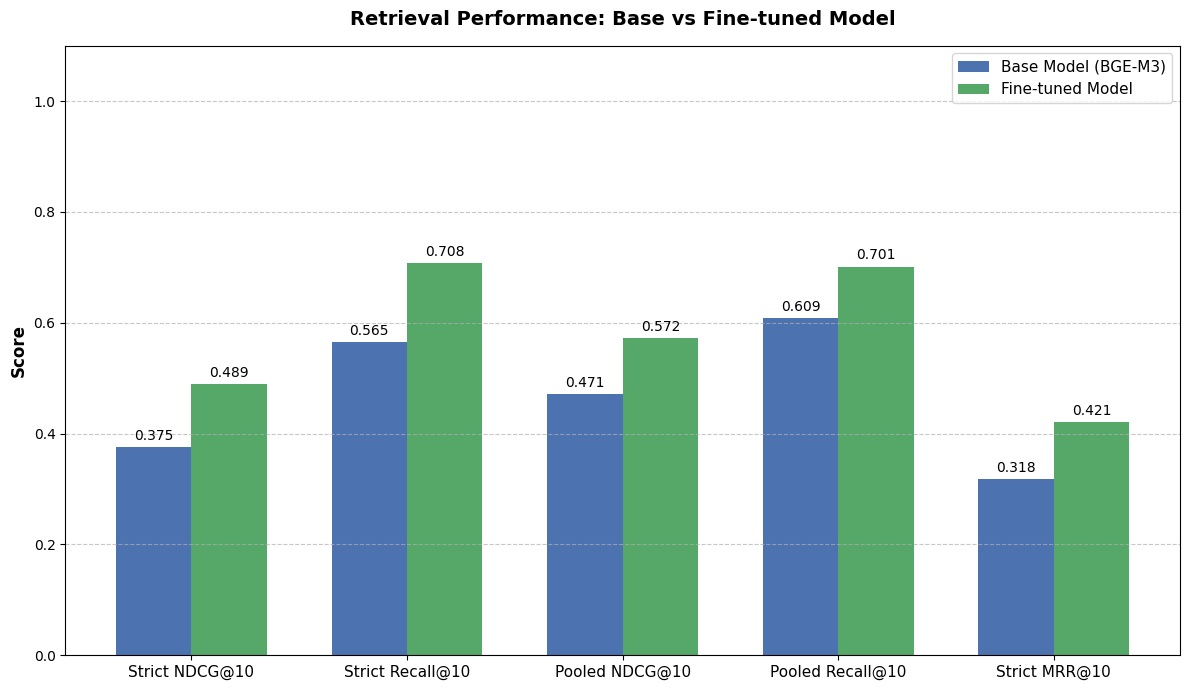

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Define the metrics we want to highlight in the chart
metrics_to_plot = [
    ('Strict NDCG@10', 'strict/NDCG@10'),
    ('Strict Recall@10', 'strict/Recall@10'),
    ('Pooled NDCG@10', 'pooled/NDCG@10'),
    ('Pooled Recall@10', 'pooled/Recall@10'),
    ('Strict MRR@10', 'strict/MRR@10')
]

labels = [m[0] for m in metrics_to_plot]
keys = [m[1] for m in metrics_to_plot]

# Extract values from the metrics dictionaries
base_vals = [base_metrics.get(k, 0) for k in keys]
ft_vals = [ft_metrics.get(k, 0) for k in keys]

x = np.arange(len(labels))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots(figsize=(12, 7))
rects1 = ax.bar(x - width/2, base_vals, width, label='Base Model (BGE-M3)', color='#4C72B0')
rects2 = ax.bar(x + width/2, ft_vals, width, label='Fine-tuned Model', color='#55A868')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.set_title('Retrieval Performance: Base vs Fine-tuned Model', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11)
ax.legend(fontsize=11)
ax.set_ylim(0, 1.1) # Score is between 0 and 1
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Add the exact numbers on top of the bars
ax.bar_label(rects1, fmt='%.3f', padding=3, fontsize=10)
ax.bar_label(rects2, fmt='%.3f', padding=3, fontsize=10)

fig.tight_layout()
plt.show()

## 14. Training Loss Evolution (InfoNCE)

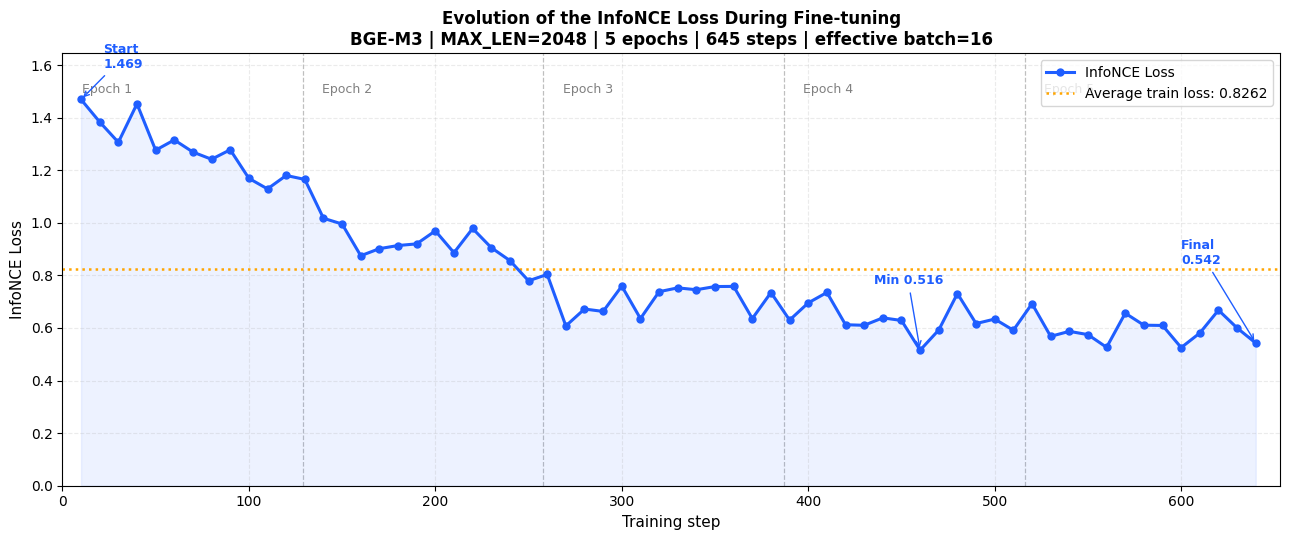

Saved: /content/infonce_loss_curve.png | logged points: 64 | first=1.469 final=0.542 avg=0.8262


In [ ]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ── Read the training log saved by the Trainer in the last checkpoint ─────────
ckpts = sorted(Path(OUTPUT_DIR).glob("checkpoint-*"), key=lambda d: int(d.name.split("-")[1]))
state = json.load(open(ckpts[-1] / "trainer_state.json", encoding="utf-8"))

logs   = [h for h in state["log_history"] if "loss" in h and "step" in h]
steps  = np.array([h["step"] for h in logs])
losses = np.array([float(h["loss"]) for h in logs])

max_steps       = state["max_steps"]
n_epochs        = int(round(state["num_train_epochs"]))
steps_per_epoch = max_steps / n_epochs
avg_loss = next((h["train_loss"] for h in state["log_history"] if "train_loss" in h), float(losses.mean()))
eff_batch = BATCH_SIZE * GRAD_ACCUM if "BATCH_SIZE" in globals() else 16
max_len   = MAX_LEN if "MAX_LEN" in globals() else 2048

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(steps, losses, "-o", color="#1f5eff", lw=2.2, ms=5, label="InfoNCE Loss", zorder=3)
ax.fill_between(steps, losses, color="#1f5eff", alpha=0.08, zorder=1)
ax.axhline(avg_loss, color="orange", ls=":", lw=1.8, label=f"Average train loss: {avg_loss:.4f}", zorder=2)

# Epoch boundaries
ymax = max(losses.max() * 1.12, 1.0)
for e in range(1, n_epochs + 1):
    x = (e - 1) * steps_per_epoch
    if e > 1:
        ax.axvline(x, color="gray", ls="--", lw=0.9, alpha=0.5, zorder=0)
    ax.text(x + steps_per_epoch * 0.08, ymax * 0.93, f"Epoch {e}", color="gray", fontsize=9, va="top")

# Annotations: start, minimum and final
ax.annotate(f"Start\n{losses[0]:.3f}", (steps[0], losses[0]), xytext=(steps[0] + 12, losses[0] + 0.12),
            color="#1f5eff", fontsize=9, fontweight="bold", arrowprops=dict(arrowstyle="->", color="#1f5eff"))
i_min = int(losses.argmin())
if i_min != len(losses) - 1:
    ax.annotate(f"Min {losses[i_min]:.3f}", (steps[i_min], losses[i_min]), xytext=(steps[i_min] - 25, losses[i_min] + 0.25),
                color="#1f5eff", fontsize=9, fontweight="bold", arrowprops=dict(arrowstyle="->", color="#1f5eff"))
ax.annotate(f"Final\n{losses[-1]:.3f}", (steps[-1], losses[-1]), xytext=(steps[-1] - 40, losses[-1] + 0.3),
            color="#1f5eff", fontsize=9, fontweight="bold", arrowprops=dict(arrowstyle="->", color="#1f5eff"))

ax.set_xlim(0, max_steps + 8)
ax.set_ylim(0, ymax)
ax.set_xlabel("Training step", fontsize=11)
ax.set_ylabel("InfoNCE Loss", fontsize=11)
ax.set_title("Evolution of the InfoNCE Loss During Fine-tuning\n"
             f"BGE-M3 | MAX_LEN={max_len} | {n_epochs} epochs | {max_steps} steps | effective batch={eff_batch}",
             fontsize=12, fontweight="bold")
ax.grid(alpha=0.25, ls="--")
ax.legend(loc="upper right")
plt.tight_layout()

out_png = "/content/infonce_loss_curve.png"
plt.savefig(out_png, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {out_png} | logged points: {len(steps)} | first={losses[0]:.3f} final={losses[-1]:.3f} avg={avg_loss:.4f}")